<center>

## ARHITEKTURE NEURONSKIH MREŽA
## Vježba 3 <br>**Unaprijedne neuronske mreže**
*(engl. Feedforward netoworks)*



</center>



In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

## Prisjetimo se: **Perceptron**

> *Matematički model neurona*



<center>
<br>
<img alt='FF' src='https://drive.google.com/uc?id=1rffcp82yWTqlQXSnAiL5wagguwV7QnyH', width = '50%'/>
</center>

Aktivacijska funkcija $\varphi$ koju smo koristili:

- **STEP funkcija**  <br><br>

<center>
  $\quad\quad S(z)=
\begin{cases}
    1, & \text{ako je } z\geq 0\\
    0, & \text{u protivnom}
\end{cases}$
<br><br>
<img src = 'https://upload.wikimedia.org/wikipedia/commons/a/af/Asymptote_Heaviside_function.png' width='400px'/>
</center>



> **Ograničenja/nedostaci** perceptrona:
>- *ne može naučiti problem koji nije linearno razdvojiv*,
>- izlaz poprima samo dvije vrijednosti 0 i 1,
>- mala promjena ulaza može rezultirati značajnom promjenom izlaza.


Za razliku od perceptrona, **unaprijedne neuronske mreže** mogu naučiti granice koje **nisu linearne**.

# Unaprijedne neuronske mreže

---

## Arhitektura unaprijedne neuronske mreže

<br>
<img alt='FF' src='https://drive.google.com/uc?id=1JgHNONCLU8FBoT-dwIykNSaybflDmdY1', width = '60%'/>



- Slojevi neuronske mreže:
  - ulazni sloj
  - skriveni slojevi
  - izlazni sloj.
- Neuroni koji pripadaju istom sloju koriste **istu** aktivacijsku funkciju $\varphi$.
- Slojevi su **potpuno povezani** (engl. *Fully-Connected*, *FC*).
- Svaki neuron sadrži numeričku vrijednost koju prosljeđuje *naprijed neuronima u višim slojevima* (**unaprijedna** neuronska mreža).



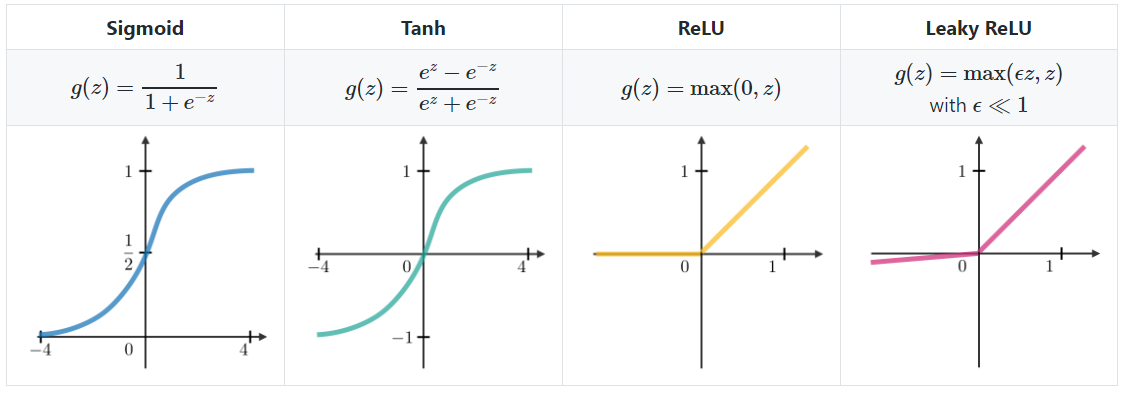



## Problem klasifikacije znamenki na slikama

Koristit ćemo **MNIST** skup podataka koji se sastoji od 70000 28x28 grayscale slika podijeljenih u 10 kategorija koje odgovaraju znamenkama 0-9.

> *"Hello World"* dubinskog strojnog učenja.

Skenirane slike rukom pisanih znamenaka.
> U skupu za testiranje nalaze se znamenke koje su napisale osobe "čije znamenke" **nisu u skupu za treniranje**.

In [ ]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

In [ ]:
print(X_train.shape)
print(X_test.shape)

(60000, 28, 28)
(10000, 28, 28)


In [ ]:
X_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 170,
        253, 253, 253, 253, 253, 225, 172, 253, 242, 195,  64,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  49, 238, 253, 253, 253, 253,
        253, 253, 253, 253, 251,  93,  82,  82,  56,  39,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  18, 219, 253, 253, 253, 253,
        253, 198, 182, 247, 241,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  80, 156, 107, 253, 253,
        205,  11,   0,  43, 154,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,  14,   1, 154, 253,
         90,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 139, 253,
        190,   2,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  11, 190,
        253,  70,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  35,
        241, 225, 160, 108,   1,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         81, 240, 253, 253, 119,  25,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  45, 186, 253, 253, 150,  27,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,  16,  93, 252, 253, 187,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 249, 253, 249,  64,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  46, 130, 183, 253, 253, 207,   2,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  39,
        148, 229, 253, 253, 253, 250, 182,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  24, 114, 221,
        253, 253, 253, 253, 201,  78,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  23,  66, 213, 253, 253,
        253, 253, 198,  81,   2,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,  18, 171, 219, 253, 253, 253, 253,
        195,  80,   9,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,  55, 172, 226, 253, 253, 253, 253, 244, 133,
         11,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0, 136, 253, 25

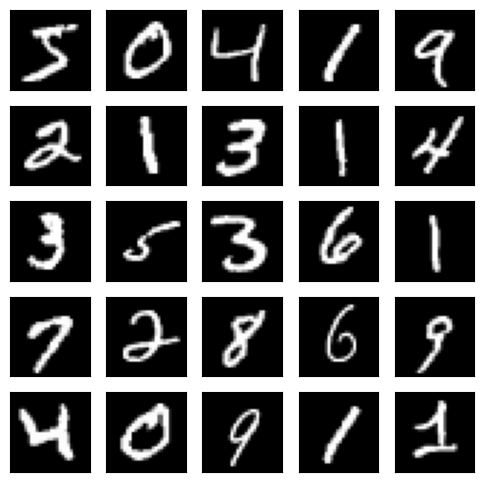

In [ ]:
# prvih 25 slika iz skupa za treniranje
fig = plt.figure(figsize=(6, 6))  # velicina slike u incima
for i in range(25):
    ax = fig.add_subplot(5, 5, i + 1, xticks=[], yticks=[])
    ax.imshow(X_train[i], cmap='gray')

### Priprema podataka



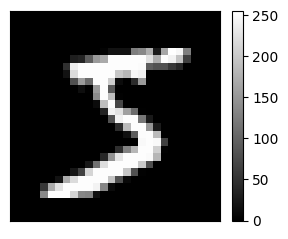

In [ ]:
plt.figure(figsize = (3,3))
im = plt.imshow(X_train[0], cmap='gray')
plt.xticks([]), plt.yticks([])
plt.colorbar(im, fraction=0.045)
plt.grid(False)
plt.show()

In [ ]:
print(X_train.dtype)
print(f'min: {np.min(X_train)}, max: {np.max(X_train)}')

uint8
min: 0, max: 255


Podaci iz skupa za treniranje pohranjeni su u array oblika $(60000, 28, 28)$ tipa `uint8` s vrijednostima u $[0,255]$.
- Podatke transformiramo u `flaot32` array istog oblika s vrijednostima u $[0,1]$.

In [ ]:
X_train = X_train.astype('float32') / 255.0

Analgno napravimo i sa skupom za testiranje



In [ ]:
X_test = X_test.astype('float32') / 255.0

### Implementirajmo neuronsku mrežu za klasifikaciju znamenki

In [ ]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

#### Softmax aktivacijska funkcija
modelira distribuciju vjerojatnosti po klasama.
> *izlazni sloj kod višeklasne klasifikacije*


<br>
<img alt='softmax.png' src='https://drive.google.com/uc?id=1uqz-qfeDDE25RU-ckzumDCSc7-wYhFg8' width='50%'>


In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,050 (215.04 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
64*784+64

50240

In [ ]:
y_train

array([5, 0, 4, ..., 5, 6, 8], dtype=uint8)

In [ ]:
# kompajliramo model
model.compile(
    loss='categorical_crossentropy',
    optimizer='sgd',
    metrics=['accuracy']
  )

- `loss`: funkcija koja se minimizira za vrijeme treniranja
- `optimizer`: algoritam koji određuje na koji način će se težine mreže za vrijeme treniranja ažurirati s ciljem smanjenja `loss`-a na podacima iz skupa za treniranje
- `metrics`: metrika koja se (uz `loss`) prati za vrijeme treniranja

**Categorical-crossentropy** loss
- "mjeri razliku dviju distribucija" (koristimo je za problem **višeklasne klasifikacije**)
$$L(\boldsymbol{\hat{y}, \boldsymbol{y}}) = - \sum\limits_{i=0}^{9}y_i\log\hat{y}_i$$
- zahtijeva **one-hot** kodiranje labela.
><img src ='https://drive.google.com/uc?id=1ty7gt7EI2bgkvW5bcoIbxJNjc7zFIikd' alt='onehot' width='70%'>




Koristimo [`tf.keras.utils.to_categorical`](https://www.tensorflow.org/api_docs/python/tf/keras/utils/to_categorical)

In [ ]:
y_train[:5]

array([5, 0, 4, 1, 9], dtype=uint8)

In [ ]:
tf.keras.utils.to_categorical(y_train)[:5]

array([[0., 0., 0., 0., 0., 1., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 1.]])

#### Treniranje modela

Metoda `fit` koju pozivamo za treniranje mreže kao rezultat vraća `History` objekt.

- u atributu `history` `History` objekta (`History.history`) su spremljeni zapisi/logovi vrijednosti *loss*-a i ostalih metrika koje se prate po epohama.


In [ ]:
povijest = model.fit(X_train, tf.keras.utils.to_categorical(y_train), epochs=10, batch_size=32)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8082 - loss: 0.7210
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9071 - loss: 0.3242
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9224 - loss: 0.2675
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9324 - loss: 0.2327
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9397 - loss: 0.2074
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9458 - loss: 0.1870
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9499 - loss: 0.1712
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9542 - loss: 0.1570
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9577 - loss: 0.1455
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9613 - loss: 0.1352


#### SGD (*stohastic gradient descent*)

> **Ideja:** ažuriraj težine u smjeru negativnog gradijenta

$$\boldsymbol{w}^{(k+1)} \leftarrow \boldsymbol{w}^{(k)} - \alpha \cdot \nabla_\boldsymbol{w} J(\boldsymbol{w}^{(k)}; \text{podaci})$$

- $J$ - funkcija cijene (prosječan `loss` na podacima)
- $\alpha$ - stopa učenja

<br>

<center>
<img src = 'https://images.deepai.org/glossary-terms/dd6cdd6fcfea4af1a1075aac0b5aa110/sgd.png' width=50%>
</center>

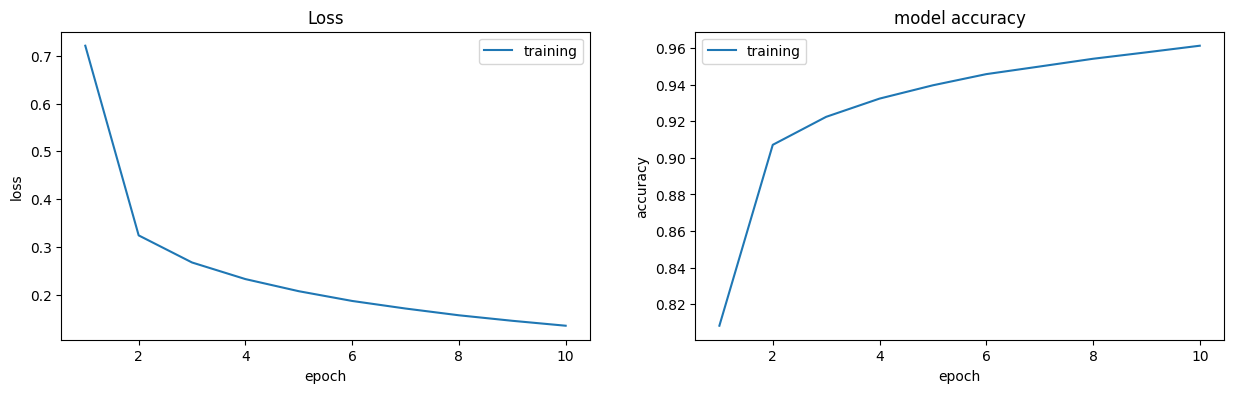

In [ ]:
fig = plt.figure(figsize = (15,4))

plt.subplot(1, 2, 1)
plt.title("Loss")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.plot(range(1,11), povijest.history["loss"], label="training")
plt.legend()

plt.subplot(1, 2, 2)
plt.title("model accuracy")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.plot(range(1,11), povijest.history["accuracy"], label="training")
plt.legend()

plt.show()

### Evaluacija modela

In [ ]:
test_loss, test_acc = model.evaluate(X_test, tf.keras.utils.to_categorical(y_test))
print('Test loss: {:.4f}\nTest accuracy: {:.2f}%'.format(test_loss, test_acc*100))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9609 - loss: 0.1345
Test loss: 0.1345
Test accuracy: 96.09%


In [ ]:
model.predict(np.expand_dims(X_test[0], 0))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


array([[4.8168786e-05, 1.2453924e-07, 6.1415695e-04, 3.4471101e-03,
        1.1125526e-08, 9.5232635e-06, 7.8634828e-11, 9.9579585e-01,
        1.4900122e-05, 7.0124341e-05]], dtype=float32)

In [ ]:
y_test[0]

np.uint8(7)

#### Matrica konfuzije

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [ ]:
y_test_pred = model.predict(X_test)
print(y_test_pred[:3])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
[[4.81686475e-05 1.24539000e-07 6.14155200e-04 3.44710681e-03
  1.11254845e-08 9.52324535e-06 7.86345364e-11 9.95795846e-01
  1.49000798e-05 7.01242097e-05]
 [9.42365659e-05 2.14532876e-04 9.96704400e-01 2.28188350e-03
  1.29321265e-09 4.31875415e-05 2.37881482e-04 3.06813752e-09
  4.23912716e-04 1.78113246e-09]
 [5.19991809e-05 9.83362913e-01 6.77205157e-03 7.91123894e-04
  1.40780714e-04 9.82597936e-04 8.33659607e-04 2.97665922e-03
  3.74350743e-03 3.44707747e-04]]


In [ ]:
y_test_pred = [np.argmax(x) for x in y_test_pred]
print(y_test_pred[:3])

[np.int64(7), np.int64(2), np.int64(1)]


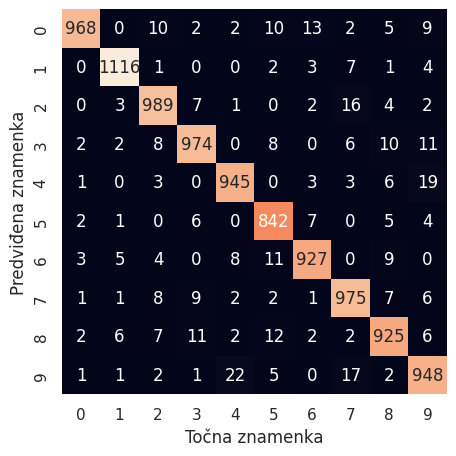

In [ ]:
mat = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(5, 5))
sns.set(font_scale=1) # malo veći font
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False)
plt.xlabel('Točna znamenka')
plt.ylabel('Predviđena znamenka')
plt.show()